# Behavioral Drift and Early Churn Prediction

In [9]:
from google.colab import files
import os

# Check if the file already exists to avoid re-uploading
file_path = '/content/telecom_customer_churn.csv'
if not os.path.exists(file_path):
    uploaded = files.upload()
    for fn in uploaded.keys():
        print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')
else:
    print(f'File {file_path} already exists. Skipping upload.')

Saving telecom_customer_churn.csv.zip to telecom_customer_churn.csv.zip
User uploaded file "telecom_customer_churn.csv.zip" with length 434006 bytes


In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE
from collections import Counter # Import Counter
import zipfile
import os

# Define the path for the zip file and the extracted CSV
zip_file_path = '/content/telecom_customer_churn.csv.zip'
csv_file_path = '/content/telecom_customer_churn.csv'

# Check if the CSV already exists, if not, try to extract it
if not os.path.exists(csv_file_path):
    if os.path.exists(zip_file_path):
        with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
            zip_ref.extractall('/content/')
        print(f'Extracted {csv_file_path} from {zip_file_path}')
    else:
        print(f'Error: {zip_file_path} not found. Please upload the zip file.')

# Load dataset
df = pd.read_csv(csv_file_path)

# Drop unnecessary columns
df.drop("Customer ID", axis=1, inplace=True)

# Handle missing values
df.dropna(inplace=True)

# Convert TotalCharges to numeric
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors='coerce')
df.dropna(inplace=True)

# Encode categorical columns
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = le.fit_transform(df[col])

# Split features & target
X = df.drop("Churn Reason", axis=1)
y = df["Churn Reason"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # Added random_state for reproducibility

# Analyze class distribution in y_train
class_counts = Counter(y_train)

# Create a sampling strategy for SMOTE
# Only oversample classes that have at least 2 samples, as SMOTE needs at least 2 samples to work with k_neighbors=1
smote_sampling_strategy = {cls: count for cls, count in class_counts.items() if count >= 2}

# Apply SMOTE only if there are classes with sufficient samples (>=2) to oversample
if smote_sampling_strategy:
    # Set k_neighbors=1 for robustness, allowing SMOTE to work for classes with only 2 samples
    sm = SMOTE(random_state=42, k_neighbors=1, sampling_strategy=smote_sampling_strategy)
    X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
else:
    print("No classes with sufficient samples (>=2) for SMOTE oversampling. Proceeding without SMOTE.")
    X_train_res, y_train_res = X_train, y_train

# Model
model = RandomForestClassifier()
model.fit(X_train_res, y_train_res)

# Predictions
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

Extracted /content/telecom_customer_churn.csv from /content/telecom_customer_churn.csv.zip
Accuracy: 0.44525547445255476


In [6]:
# Install imbalanced-learn library if not already installed
!pip install imbalanced-learn

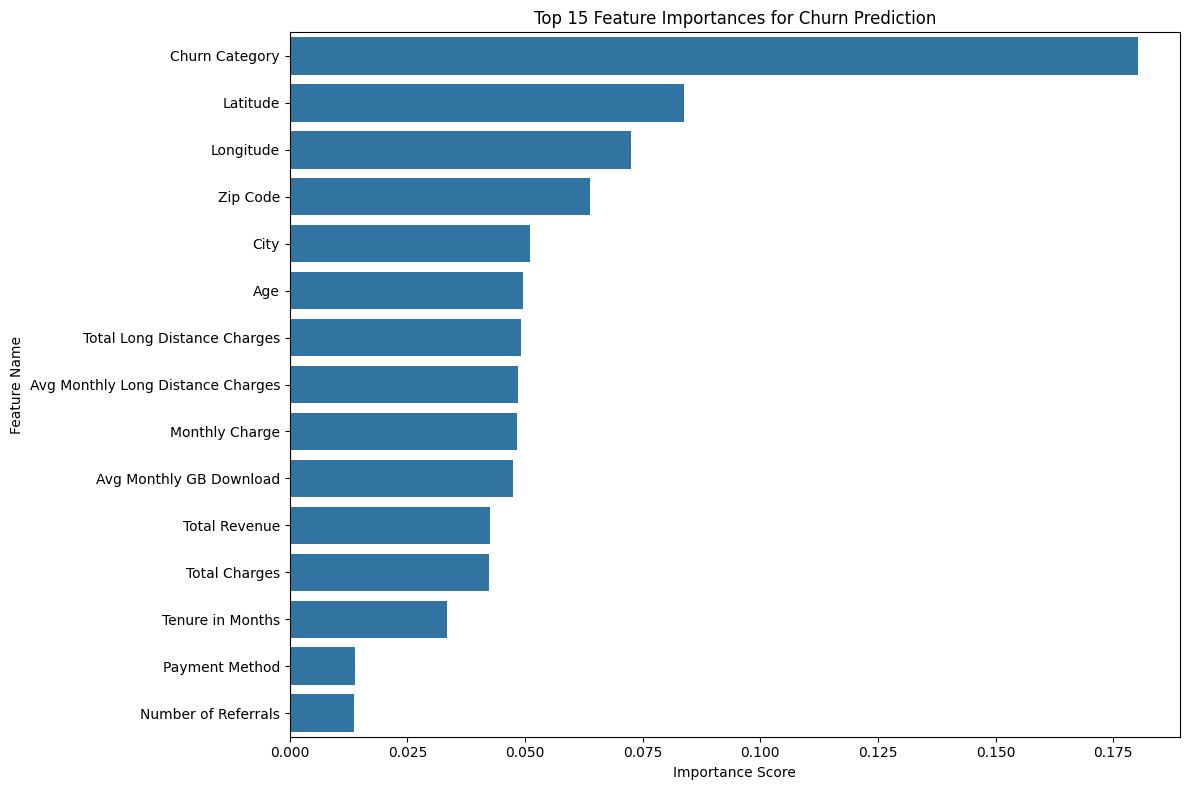

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importances from the trained model
feature_importances = model.feature_importances_

# Get feature names from the training data
feature_names = X_train.columns

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})

# Sort by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot the top N features (e.g., top 15)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(15))
plt.title('Top 15 Feature Importances for Churn Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print the confusion matrix
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 1  7  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  8  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 18  4  0  3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  9 21  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  5  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  6  1  1  3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  1  0  0  3  0  0  0  0  0  1  1  0  1  1  0]
 [ 0  0  0  0  0  0  1  0  0  0  0  1  0  0  0  1  0  0]
 [ 0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  2  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  1  1  0  0  0]
 [ 0  0  0  1  0  0  0  0  0  0  0  1  0  0  0  0  0  1]
 [ 0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  1  0  1]
 [ 0  0  0  0  0  0  2  0  0  0  0  0  0  1  0  0  0  0]
 [ 0  0  3  0  0  0  0  0  0  0  0  0  0  2  0  0  3  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0]
 [ 0  0  0  0  0  0  0  1  0  0  0  0  1  0  0  2  0  0]
 [ 0  0  1  1  0  0  0  0  0  0  0  0  0  0  0  0  1  0]
 [ 0  0  1  0

In [15]:
from sklearn.metrics import classification_report

# Calculate the classification report, setting zero_division to 0
report = classification_report(y_test, y_pred, zero_division=0)

# Print the classification report
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.12      0.17         8
           1       0.53      0.73      0.62        11
           2       0.42      0.72      0.53        25
           3       0.72      0.70      0.71        30
           4       0.50      0.17      0.25         6
           5       0.50      0.27      0.35        11
           7       0.43      0.38      0.40         8
           8       0.00      0.00      0.00         3
           9       0.00      0.00      0.00         3
          10       0.00      0.00      0.00         2
          11       0.00      0.00      0.00         3
          12       0.00      0.00      0.00         4
          13       0.00      0.00      0.00         3
          14       0.29      0.25      0.27         8
          15       0.00      0.00      0.00         1
          17       0.29      0.50      0.36         4
          18       0.20      0.33      0.25         3
    

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


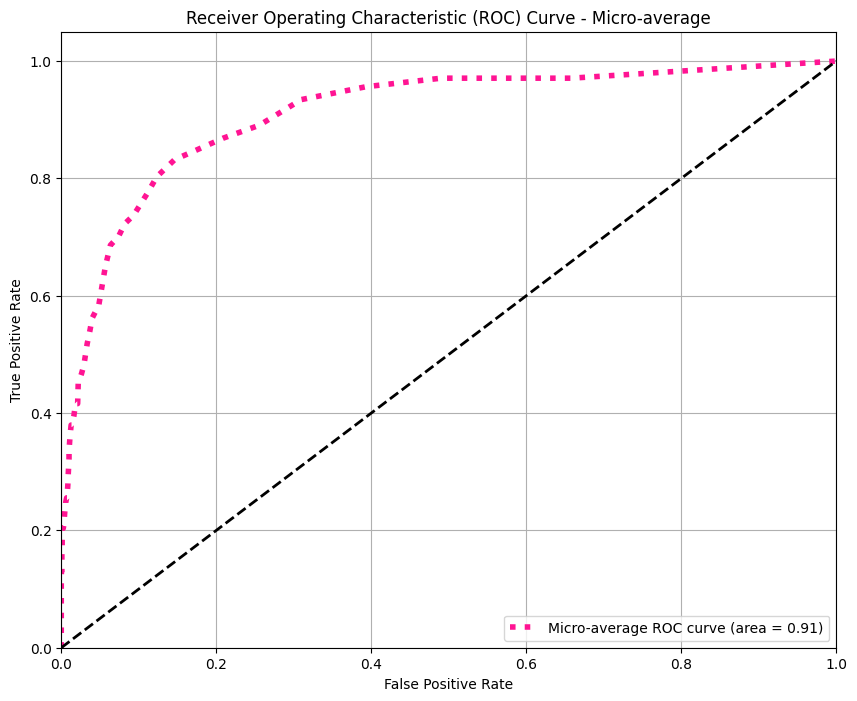

In [16]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Ensure 'y' is defined for n_classes, assuming 'df' is available from previous cells.
y = df["Churn Reason"]

# For multi-class classification, calculate one-vs-rest ROC AUC
# Binarize the output
from sklearn.preprocessing import label_binarize

n_classes = len(np.unique(y))
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
y_pred_proba = model.predict_proba(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_pred_proba.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr["micro"], tpr["micro"],
         label=f'Micro-average ROC curve (area = {roc_auc["micro"]:0.2f})',
         color='deeppink', linestyle=':', linewidth=4)

# You can plot individual class ROC curves if desired, but for many classes, it can be messy
# for i in range(n_classes):
#     plt.plot(fpr[i], tpr[i], lw=2,
#              label='ROC curve of class {0} (area = {1:0.2f})'
#              ''.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Micro-average')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
# Simulate behavioral drift (example logic)
def detect_drift(prev_usage, current_usage):
    if current_usage < prev_usage * 0.6:
        return 1  # Drift detected
    return 0

# Example: simulate for first 5 users
for i in range(5):
    prev_usage = X_test.iloc[i]["Monthly Charge"]
    current_usage = prev_usage * 0.5  # simulate drop

    drift = detect_drift(prev_usage, current_usage)
    churn_pred = y_pred[i]

    if churn_pred == 1 and drift == 1:
        risk = "HIGH"
    elif churn_pred == 1:
        risk = "MEDIUM"
    else:
        risk = "LOW"

    print(f"Customer {i} → Risk: {risk}")

Customer 0 → Risk: LOW
Customer 1 → Risk: LOW
Customer 2 → Risk: LOW
Customer 3 → Risk: LOW
Customer 4 → Risk: HIGH


In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 111.4 MB/s eta 0:00:00


In [ ]:
import streamlit as st
from sklearn.metrics import accuracy_score, classification_report

st.title("Churn Prediction System")

if st.button("Run Prediction"):
    st.write("Model Accuracy:", accuracy_score(y_test, y_pred))
    st.subheader("Classification Report:")
    st.text(classification_report(y_test, y_pred, zero_division=0))

2026-04-06 12:35:14.241 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-06 12:35:14.394 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-04-06 12:35:14.395 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-06 12:35:14.396 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-06 12:35:14.398 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-06 12:35:14.399 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-06 12:35:14.400 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-06 12:35:14.402 Thread 'MainThread': mi

In [ ]:
# Install localtunnel
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
added 22 packages in 4s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇

In [ ]:
import subprocess
import threading
import time

# Define the command to run your Streamlit app
# Note: The actual path to your script will be /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py
# This is based on the warning message you received earlier.
streamlit_command = [
    "streamlit", "run", "/usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py",
    "--server.port", "8501", # Specify a port for Streamlit
    "--server.enableCORS", "false", # Disable CORS for localtunnel
    "--server.enableXsrfProtection", "false" # Disable XSRF for localtunnel
]

# Function to run Streamlit in a separate thread
def run_streamlit():
    print("Starting Streamlit app in background...")
    process = subprocess.Popen(streamlit_command, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    # Optionally, you can print stdout/stderr if you want to see Streamlit's logs
    # for line in process.stdout:
    #     print(line.decode().strip())
    # for line in process.stderr:
    #     print(line.decode().strip())
    process.wait() # Wait for the process to complete (it won't if the app runs continuously)

# Start Streamlit in a new thread
streamlit_thread = threading.Thread(target=run_streamlit)
streamlit_thread.daemon = True # Allow main program to exit even if thread is running
streamlit_thread.start()

print("Waiting for Streamlit app to start (5 seconds)...")
time.sleep(5) # Give Streamlit some time to start up
print("Streamlit app should be running in the background.")

Starting Streamlit app in background...
Waiting for Streamlit app to start (5 seconds)...
Streamlit app should be running in the background.


In [ ]:
# Start localtunnel to expose the Streamlit port
# This will provide a URL to access your Streamlit app
!lt --port 8501

your url is: https://neat-cows-look.loca.lt
^C


In [ ]:
print(X_test.columns)

Index(['Gender', 'Age', 'Married', 'Number of Dependents', 'City', 'Zip Code',
       'Latitude', 'Longitude', 'Number of Referrals', 'Tenure in Months',
       'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges',
       'Multiple Lines', 'Internet Service', 'Internet Type',
       'Avg Monthly GB Download', 'Online Security', 'Online Backup',
       'Device Protection Plan', 'Premium Tech Support', 'Streaming TV',
       'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract',
       'Paperless Billing', 'Payment Method', 'Monthly Charge',
       'Total Charges', 'Total Refunds', 'Total Extra Data Charges',
       'Total Long Distance Charges', 'Total Revenue', 'Customer Status',
       'Churn Category'],
      dtype='object')
